In [1]:
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
from deep_isochron.analysis.ode import find_limit_cycle, floquet
from deep_isochron.data import (
    resolve_device,
)
from deep_isochron.plotting import configure_rcparams
from deep_isochron.systems import FitzhughNagumo


jax.config.update("jax_enable_x64", True)
device = resolve_device(
    3
)  # the card the scheduler assigned; refuses to guess on a shared node
jax.config.update("jax_default_device", device)
configure_rcparams()

# The limit cycle of FitzHugh–Nagumo and its Floquet multipliers

O1 (`find_limit_cycle`) and O2 (`floquet`); the prototyping code that preceded them lives in `tests/test_analysis_ode.py` and `analysis/ode/floquet.py`.

In [2]:
ode = FitzhughNagumo()
cycle = find_limit_cycle(ode, jnp.asarray([3.0, 3.0]), t_settle=10.0, m=10)
cycle.period, cycle.orientation()

E1028 12:27:17.566285  800046 cuda_executor.cc:1348] [3] Failed to allocate device memory of 23.80GiB (25555894272 bytes): RESOURCE_EXHAUSTED: : CUDA_ERROR_OUT_OF_MEMORY: out of memory
=== Source Location Trace: ===
external/xla+/xla/stream_executor/cuda/cuda_status.cc:45
external/xla+/xla/stream_executor/cuda/cuda_device_allocator.cc:226
external/xla+/xla/stream_executor/cuda/cuda_device_allocator.cc:389



(Array(11.22788676, dtype=float64), -1)

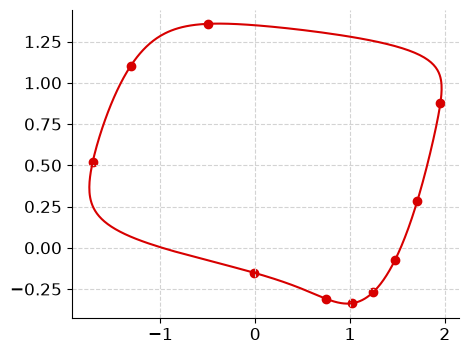

In [3]:
times, points = cycle.sample(512)
fig, ax = plt.subplots(1, 1, figsize=(5, 4))
ax.plot(*points.T)
ax.scatter(*cycle.x0s.T)

In [4]:
for method in ("periodic_schur", "monodromy", "liouville"):
    fl = floquet(cycle, method=method)
    print(method, fl.multipliers, fl.exponents, fl.trivial_error, fl.closure)

periodic_schur [1.00000000e+00 1.69059036e-12] [ 5.39080812e-11 -2.41416251e+00] 6.05273831055797e-10 2.6581664292158038e-11
monodromy [1.00000000e+00 1.69042558e-12] [ 5.31331915e-11 -2.41417119e+00] 5.965734573010195e-10 None
liouville [1.00000000e+00 1.69059036e-12] [ 0.         -2.41416251] None None


# The asymptotic phase fields of fhn and fhn-easy

O3 by forward integration and a read-off on the cycle (`phase_grid`, route (a) of
`docs/design/analysis.md` §4). The cycle and phase 0 come from the isochron configs
(`isochron_cycle`), so the field, the AUTO isochrons and the model are compared on one
phase origin; `t_end` is the config's `phase_field.t_end`. Masked points are those
whose two readings, one period apart, differ by 1e-6 or more, or whose orbit has not
come within 1e-6 of the cycle: near the source, and wherever `t_end` falls short.
Run under float64 (first cell); on two CPU cores a 200 × 200 grid takes about a
minute per system.

In [ ]:
import time

import numpy as np
from deep_isochron.analysis.ode import asymptotic_phase, phase_grid
from deep_isochron.experiment import (
    compose,
    compose_group,
    isochron_config,
    isochron_cycle,
    load_isochrons,
)


def isochron_cfg(name, *overrides):
    """The isochron config of `name` as its schema object (``cfg.file()`` is the
    foliation's file)."""
    return isochron_config(compose(*overrides, config_name=f"isochrons/{name}"))


xs = ys = jnp.linspace(-3.0, 3.0, 200)
fields = {}
for name in ("fhn", "fhn-easy"):
    cfg = isochron_cfg(name)
    cycle = isochron_cycle(cfg)
    t_end = compose_group("phase_field", name).t_end
    start = time.perf_counter()
    field, mask, result = phase_grid(cycle, xs, ys, t_end=t_end)

    fields[name] = (cfg, cycle, np.asarray(field), np.asarray(mask), result)
    print(
        f"{name}: T = {float(cycle.period):.6f}, masked {int((~mask).sum())} of "
        f"{mask.size}, {time.perf_counter() - start:.0f} s"
    )

In [ ]:
from deep_isochron.plotting import plot_phase_field


fig, axes = plt.subplots(1, 2, figsize=(11, 5), constrained_layout=True)
for ax, (name, (cfg, cycle, field, mask, _)) in zip(axes, fields.items(), strict=True):
    isochrons = load_isochrons(cfg).isochrons if cfg.file().exists() else ()
    image = plot_phase_field(ax, xs, ys, field, cycle, isochrons, every=10)
    ax.set(title=name)
fig.colorbar(image, ax=axes, label=r"Asymptotic phase $\Theta$ (turns)")

Check against AUTO (when the config's `.nc` exists): the phase at the points of each
isochron within 0.01 of the cycle, against the isochron's phase. Farther out, near the
source, a stored point's position error times the steep phase gradient there grows
to a sixth of a turn (`tests/test_phase.py`).

In [ ]:
from deep_isochron.utils.numerics import phase_difference


for name, (cfg, cycle, *_) in fields.items():
    if not cfg.file().exists():
        print(f"{name}: no isochron file at {cfg.file()}")
        continue
    t_end = compose_group("phase_field", name).t_end
    _, samples = cycle.sample(4096)
    read = jax.jit(jax.vmap(lambda x: asymptotic_phase(cycle, x, t_end=t_end)))
    gaps = []
    for iso in load_isochrons(cfg).isochrons:
        d = np.linalg.norm(iso.points[:, None] - np.asarray(samples)[None], axis=2)
        near = iso.points[d.min(axis=1) < 0.01]
        if len(near):
            phase = np.asarray(read(jnp.asarray(near)).phase)
            gaps.append(np.abs(phase_difference(phase, iso.phase)).max())
    print(f"{name}: {len(gaps)} isochrons, largest gap {max(gaps):.2e} turns")

Comparison with a trained model. Fill in the run directories. A model's phase has its
own origin and may run either way round the cycle, so the reference is aligned to it
by a circular-mean offset for each direction, and the direction with the smaller
residual is kept. `load_model` applies the run's own `x64` and device settings, so the
reference fields above are computed first and kept as NumPy arrays.

In [ ]:
from deep_isochron.experiment import load_model
from deep_isochron.plotting import plot_phase_comparison


RUN_DIRS = {
    "fhn": "./runs/fhn2",
    "fhn-easy": "./runs/fhn_easy",
}  # the run directories of the trained models

for name, run_dir in RUN_DIRS.items():
    if run_dir is None:
        continue
    cfg, cycle, field, mask, _ = fields[name]
    model = load_model(run_dir)
    isochrons = load_isochrons(cfg).isochrons if cfg.file().exists() else ()
    fig, result = plot_phase_comparison(
        xs, ys, field, cycle, model, isochrons, name=name
    )
    a = result.alignment
    print(
        f"{name}: sense {a.sense:+.0f}, offset {a.offset:.4f} rad "
        f"max {np.nanmax(np.abs(a.residual)):.3e} rad"
    )
    if len(result.isochron_gaps):  # an isochron is a level set of the model's phase
        print(
            "  on the AUTO isochrons: median gap "
            f"{np.median(result.isochron_gaps):.3e}, "
            f"max {result.isochron_gaps.max():.3e} rad"
        )

In [ ]:
# A learned isochron is `model.isochron(theta, r)`, the model's own; the matched points
# of a reference isochron are
# `model.isochron(theta, model.isochron_coordinate(points))`.


In [ ]:
for name, run_dir in RUN_DIRS.items():
    if run_dir is None:
        continue
    model = load_model(run_dir)
    # the phase -pi/4 rad, as a turn
    iso_learned = model.isochron(jnp.asarray(0.875), jnp.linspace(0.1, 2, 100))
    plt.plot(*np.asarray(iso_learned).T)

## Compute reference isochrons and compare against the model

In [ ]:
from deep_isochron.experiment import compute_isochrons


N_ISOCHRONS = 5  # phases k/5 in turns; their own file, by the config hash

references = {}
for name in ("fhn", "fhn-easy"):
    cfg = isochron_cfg(name, f"phases.count={N_ISOCHRONS}")
    if cfg.file().exists():
        foliation = load_isochrons(cfg)
    else:
        start = time.perf_counter()
        foliation = compute_isochrons(cfg)  # AUTO-07p, one CPU worker per phase
        print(
            f"{name}: traced in {time.perf_counter() - start:.0f} s, "
            f"saved to {cfg.file()}"
        )
    for failure in foliation.failures:
        print(f"{name}: phase {failure.phase:+.4f} failed: {failure.message}")
    references[name] = foliation

In [ ]:
from deep_isochron.plotting import plot_isochron_match


for name, run_dir in RUN_DIRS.items():
    foliation = references[name]
    model = load_model(run_dir)
    fig, gaps = plot_isochron_match(foliation, model, name=name)
    for iso, gap in zip(foliation.isochrons, gaps, strict=True):
        # Is the AUTO isochron a level set of the model's phase?
        print(
            f"  {name} phase {iso.phase:+.3f}: "
            f"max gap on the AUTO points {gap:.2e} turns"
        )

In [ ]:
from deep_isochron.plotting import plot_isochron_hairpins


ISO_INDEX = None  # None: the isochron that comes closest to the equilibrium
MIN_EXCURSION = 0.05  # turns; a smaller reversal of the angle is not a hairpin
ZOOM_HALF = None  # half-width of the zoom about q; None: 1.5 × the farthest hairpin

In [ ]:
for name, run_dir in RUN_DIRS.items():
    foliation = references[name]
    model = load_model(run_dir)
    fig, match = plot_isochron_hairpins(
        foliation,
        model,
        index=ISO_INDEX,
        min_excursion=MIN_EXCURSION,
        zoom_half_width=ZOOM_HALF,
        name=name,
    )
    iso = foliation.isochrons[match.index]
    labels = "ABCDEFGHIJKLMNOPQRSTUVWXYZ"[: len(match.hairpins)]
    print(
        f"{name}: isochron {match.index} at phase {iso.phase:+.3f}; |H⁻¹(0) − q| = "
        f"{np.linalg.norm(match.model_equilibrium - match.equilibrium):.3f}; "
        f"{len(match.hairpins)} hairpins at "
        + ", ".join(
            f"{labels[i]}: L {iso.arclength[t]:+.3f}"
            for i, t in enumerate(match.hairpins)
        )
    )